# EnergyPredict AI — Entrenamiento y Evaluación de Modelos

## 1. Introducción

### Objetivo

El objetivo de este notebook es desarrollar y evaluar modelos de Machine Learning capaces de predecir la demanda eléctrica media de España con una hora de antelación.

Se utilizará el dataset generado durante la fase de ingeniería de características, que contiene variables de calendario, retardos temporales y estadísticas móviles de la demanda.

### Metodología

El proceso de modelado seguirá las siguientes etapas:

1. Carga y comprobación del dataset.
2. División cronológica en entrenamiento, validación y prueba.
3. Construcción de un modelo de referencia (*baseline*).
4. Entrenamiento de modelos de regresión.
5. Comparación mediante métricas de evaluación.
6. Análisis de errores y selección del modelo.

### Métricas de evaluación

Se utilizarán tres métricas principales:

- **MAE (Mean Absolute Error):** error absoluto medio, expresado en MW.
- **RMSE (Root Mean Squared Error):** raíz del error cuadrático medio, que penaliza especialmente los errores grandes.
- **MAPE (Mean Absolute Percentage Error):** error porcentual absoluto medio.

El objetivo será determinar si los modelos entrenados mejoran las predicciones obtenidas mediante el modelo de referencia.

### Prevención del Data Leakage

Dado que se trabaja con una serie temporal, los datos se dividirán respetando su orden cronológico.

Las observaciones futuras no se utilizarán para entrenar modelos destinados a predecir periodos anteriores.

## 2. Carga del dataset

Se carga el conjunto de datos preparado durante la fase de ingeniería de características.

El dataset contiene 8.616 observaciones, 11 variables predictoras, una variable objetivo y una columna temporal.

Antes de comenzar el entrenamiento se comprueba que las observaciones están ordenadas cronológicamente y que no existen valores nulos.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Localizar el dataset desde la carpeta notebooks
data_path = Path("../data/processed/features_spain_2024.parquet")

# Comprobar que el archivo existe
assert data_path.exists(), (
    f"No se encuentra el dataset: {data_path.resolve()}"
)

# Cargar y ordenar cronológicamente
df = pd.read_parquet(data_path)

df = df.sort_values(
    "target_datetime_utc"
).reset_index(drop=True)

# Validar el dataset
assert df["target_datetime_utc"].is_unique, (
    "Existen fechas objetivo duplicadas."
)

assert df["target_datetime_utc"].is_monotonic_increasing, (
    "Las fechas no están ordenadas."
)

assert df.isna().sum().sum() == 0, (
    "El dataset contiene valores nulos."
)

# Mostrar información
print("DATASET CARGADO CORRECTAMENTE")
print("----------------------------")
print("Dimensiones:", df.shape)
print("Valores nulos:", df.isna().sum().sum())

print("\nPeriodo temporal:")
print("Inicio:", df["target_datetime_utc"].min())
print("Fin:", df["target_datetime_utc"].max())

display(df.head())


DATASET CARGADO CORRECTAMENTE
----------------------------
Dimensiones: (8616, 13)
Valores nulos: 0

Periodo temporal:
Inicio: 2024-01-08 00:00:00+00:00
Fin: 2024-12-31 23:00:00+00:00


,target_datetime_utc,hour,day_of_week,month,is_weekend,lag_1,lag_2,lag_24,lag_168,rolling_mean_24,rolling_std_24,rolling_mean_168,target_next_hour
0,2024-01-08 00:00:00+00:00,1,0,1,0,24806.0,27351.0,22195.0,21378.0,24656.375000,3884.662571,25862.232143,22810.0
1,2024-01-08 01:00:00+00:00,2,0,1,0,22810.0,24806.0,20702.0,20286.0,24682.000000,3869.719965,25870.755952,21687.0
2,2024-01-08 02:00:00+00:00,3,0,1,0,21687.0,22810.0,19803.0,19074.0,24723.041667,3830.700066,25879.095238,21283.0
3,2024-01-08 03:00:00+00:00,4,0,1,0,21283.0,21687.0,19307.0,18261.0,24784.708333,3759.300692,25892.244048,21154.0
4,2024-01-08 04:00:00+00:00,5,0,1,0,21154.0,21283.0,19281.0,17899.0,24861.666667,3659.879253,25909.464286,21854.0


## 3. División cronológica de los datos

### Objetivo

Dividir el conjunto de datos en tres subconjuntos independientes para entrenar, seleccionar y evaluar los modelos predictivos.

Dado que estamos trabajando con una serie temporal, la división se realizará respetando el orden cronológico de las observaciones, evitando una separación aleatoria que podría introducir información del futuro durante el entrenamiento.

### Estrategia de división

- **Entrenamiento (70 %):** datos utilizados para entrenar los modelos.
- **Validación (15 %):** datos utilizados para comparar algoritmos y ajustar hiperparámetros.
- **Prueba (15 %):** datos reservados para evaluar el rendimiento final del modelo seleccionado.

Esta metodología permite simular un escenario real en el que el modelo aprende de datos históricos y realiza predicciones sobre periodos posteriores.

El conjunto de prueba no se utilizará durante la selección ni el ajuste de los modelos.

In [2]:
# Calcular los tamaños de cada conjunto
train_size = int(len(df) * 0.70)
val_size = int(len(df) * 0.15)

# División cronológica
train_df = df.iloc[:train_size].copy()

val_df = df.iloc[
    train_size:train_size + val_size
].copy()

test_df = df.iloc[
    train_size + val_size:
].copy()

# Mostrar dimensiones
print("DISTRIBUCIÓN DEL DATASET")
print("------------------------")
print(f"Entrenamiento: {len(train_df)} registros")
print(f"Validación:    {len(val_df)} registros")
print(f"Prueba:        {len(test_df)} registros")

print("\nPERIODOS TEMPORALES")
print("------------------")

for name, subset in [
    ("Entrenamiento", train_df),
    ("Validación", val_df),
    ("Prueba", test_df)
]:
    print(
        f"{name}: "
        f"{subset['target_datetime_utc'].min()} "
        f"→ {subset['target_datetime_utc'].max()}"
    )

# Comprobar que no existen solapamientos
assert (
    train_df["target_datetime_utc"].max()
    < val_df["target_datetime_utc"].min()
)

assert (
    val_df["target_datetime_utc"].max()
    < test_df["target_datetime_utc"].min()
)

print("\nDivisión cronológica validada correctamente.")


DISTRIBUCIÓN DEL DATASET
------------------------
Entrenamiento: 6031 registros
Validación:    1292 registros
Prueba:        1293 registros

PERIODOS TEMPORALES
------------------
Entrenamiento: 2024-01-08 00:00:00+00:00 → 2024-09-15 06:00:00+00:00
Validación: 2024-09-15 07:00:00+00:00 → 2024-11-08 02:00:00+00:00
Prueba: 2024-11-08 03:00:00+00:00 → 2024-12-31 23:00:00+00:00

División cronológica validada correctamente.


## 4. Modelo de referencia (Baseline)

### Objetivo

Establecer un rendimiento de referencia para evaluar posteriormente los modelos de Machine Learning.

### Modelo de persistencia

Se utiliza una estrategia de persistencia que supone que la demanda eléctrica de la siguiente hora será igual a la última demanda conocida.

La predicción se obtiene directamente de la variable `lag_1`, sin necesidad de entrenar un algoritmo.

Este enfoque resulta especialmente relevante porque, durante el análisis exploratorio, se observó una autocorrelación de 0,9495 entre observaciones consecutivas.

### Métricas de evaluación

Se utilizarán tres métricas:

- **MAE:** error absoluto medio expresado en MW.
- **RMSE:** raíz del error cuadrático medio expresada en MW, que penaliza especialmente los errores elevados.
- **MAPE:** error porcentual absoluto medio.

El baseline se evaluará sobre el conjunto de validación para establecer una referencia común antes de entrenar modelos más complejos.

El conjunto de prueba permanecerá reservado para la evaluación final.

In [3]:
# Valores reales de validación
y_val = val_df["target_next_hour"]

# Predicción: la demanda de la siguiente hora
# será igual a la última demanda conocida
baseline_pred = val_df["lag_1"]

# Calcular métricas
baseline_mae = mean_absolute_error(
    y_val,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        baseline_pred
    )
)

baseline_mape = (
    mean_absolute_percentage_error(
        y_val,
        baseline_pred
    ) * 100
)

print("RESULTADOS DEL BASELINE")
print("-----------------------")
print(f"MAE:  {baseline_mae:.2f} MW")
print(f"RMSE: {baseline_rmse:.2f} MW")
print(f"MAPE: {baseline_mape:.2f} %")


RESULTADOS DEL BASELINE
-----------------------
MAE:  936.38 MW
RMSE: 1273.22 MW
MAPE: 3.73 %


## 5. Visualización del modelo de referencia

Se comparan los valores reales de demanda eléctrica con las predicciones realizadas por el modelo de persistencia durante las primeras 168 horas del conjunto de validación.

Esta visualización permite identificar cómo se comporta el modelo ante los cambios horarios de demanda y detectar posibles diferencias durante los periodos de crecimiento o descenso pronunciado.

La representación servirá como referencia visual para comparar posteriormente los modelos de Machine Learning.

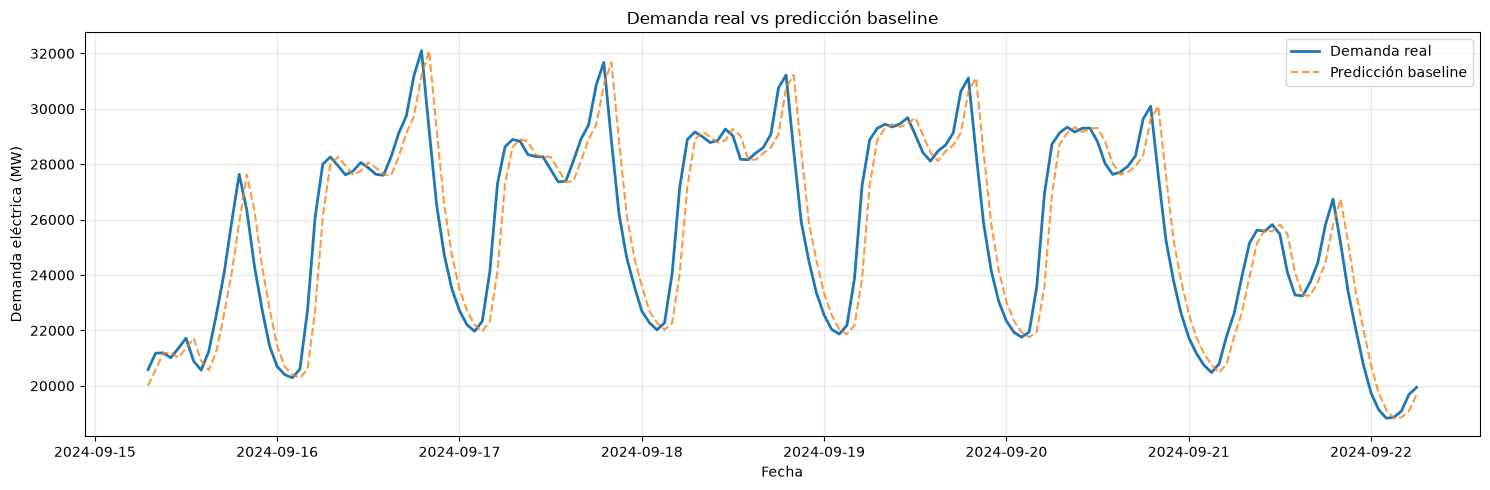

In [4]:
# Seleccionar una semana del conjunto de validación
sample = val_df.iloc[:168].copy()

plt.figure(figsize=(15, 5))

plt.plot(
    sample["target_datetime_utc"],
    sample["target_next_hour"],
    label="Demanda real",
    linewidth=2
)

plt.plot(
    sample["target_datetime_utc"],
    sample["lag_1"],
    label="Predicción baseline",
    linestyle="--",
    alpha=0.8
)

plt.title(
    "Demanda real vs predicción baseline"
)
plt.xlabel("Fecha")
plt.ylabel("Demanda eléctrica (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### 5.1. Interpretación de los resultados del baseline

El modelo de persistencia ha obtenido los siguientes resultados sobre el conjunto de validación:

| Métrica | Resultado |
|---|---:|
| MAE | 936,38 MW |
| RMSE | 1.273,22 MW |
| MAPE | 3,73 % |

El modelo presenta una capacidad razonable para seguir la evolución general de la demanda eléctrica, debido a la elevada correlación entre observaciones consecutivas.

Sin embargo, la representación gráfica muestra que las predicciones presentan un retraso temporal respecto a los valores reales.

Los errores son especialmente visibles durante los aumentos y descensos pronunciados de demanda.

**Conclusión:** el baseline constituye una referencia útil para evaluar si los modelos de Machine Learning pueden anticipar mejor las variaciones horarias y reducir el error predictivo.

## 6. Entrenamiento de un modelo de Regresión Lineal

### Objetivo

Entrenar un modelo supervisado de regresión que permita predecir la demanda eléctrica de la siguiente hora utilizando las características generadas durante la fase de Feature Engineering.

### Algoritmo seleccionado

Se utilizará `LinearRegression` de Scikit-learn.

Este algoritmo aprende una combinación lineal de las variables predictoras para estimar la demanda futura.

### Metodología

1. Seleccionar las 11 variables predictoras.
2. Separar las variables de entrada (`X`) y la variable objetivo (`y`).
3. Entrenar el modelo exclusivamente con el conjunto de entrenamiento.
4. Generar predicciones sobre el conjunto de validación.
5. Evaluar el rendimiento mediante MAE, RMSE y MAPE.

Los resultados se compararán con el modelo baseline para determinar si el aprendizaje supervisado aporta una mejora.

In [5]:
from sklearn.linear_model import LinearRegression

# Definir variables predictoras
feature_columns = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_2",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_std_24",
    "rolling_mean_168"
]

target_column = "target_next_hour"

# Separar características y objetivo
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

# Crear y entrenar el modelo
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Generar predicciones
linear_pred = linear_model.predict(X_val)

print("Modelo de regresión lineal entrenado correctamente.")
print("Predicciones generadas:", len(linear_pred))


Modelo de regresión lineal entrenado correctamente.
Predicciones generadas: 1292


In [6]:
# Calcular métricas
linear_mae = mean_absolute_error(
    y_val,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(y_val, linear_pred)
)

linear_mape = (
    mean_absolute_percentage_error(
        y_val,
        linear_pred
    ) * 100
)

print("RESULTADOS REGRESIÓN LINEAL")
print("---------------------------")
print(f"MAE:  {linear_mae:.2f} MW")
print(f"RMSE: {linear_rmse:.2f} MW")
print(f"MAPE: {linear_mape:.2f} %")

# Comparación con baseline
comparison_df = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Lineal"
    ],
    "MAE (MW)": [
        baseline_mae,
        linear_mae
    ],
    "RMSE (MW)": [
        baseline_rmse,
        linear_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        linear_mape
    ]
})

display(comparison_df.round(2))

# Mejora relativa del MAE
improvement = (
    (baseline_mae - linear_mae)
    / baseline_mae
) * 100

print(f"\nMejora del MAE respecto al baseline: {improvement:.2f} %")


RESULTADOS REGRESIÓN LINEAL
---------------------------
MAE:  500.02 MW
RMSE: 667.13 MW
MAPE: 1.94 %


,Modelo,MAE (MW),RMSE (MW),MAPE (%)
0,Baseline,936.38,1273.22,3.73
1,Regresión Lineal,500.02,667.13,1.94



Mejora del MAE respecto al baseline: 46.60 %


## 7. Comparación visual de modelos

Se comparan las predicciones de la regresión lineal con las del modelo baseline y los valores reales de demanda durante una semana del conjunto de validación.

Esta representación permite observar si el modelo supervisado consigue anticipar mejor los cambios horarios de demanda y reducir las desviaciones respecto a los valores reales.

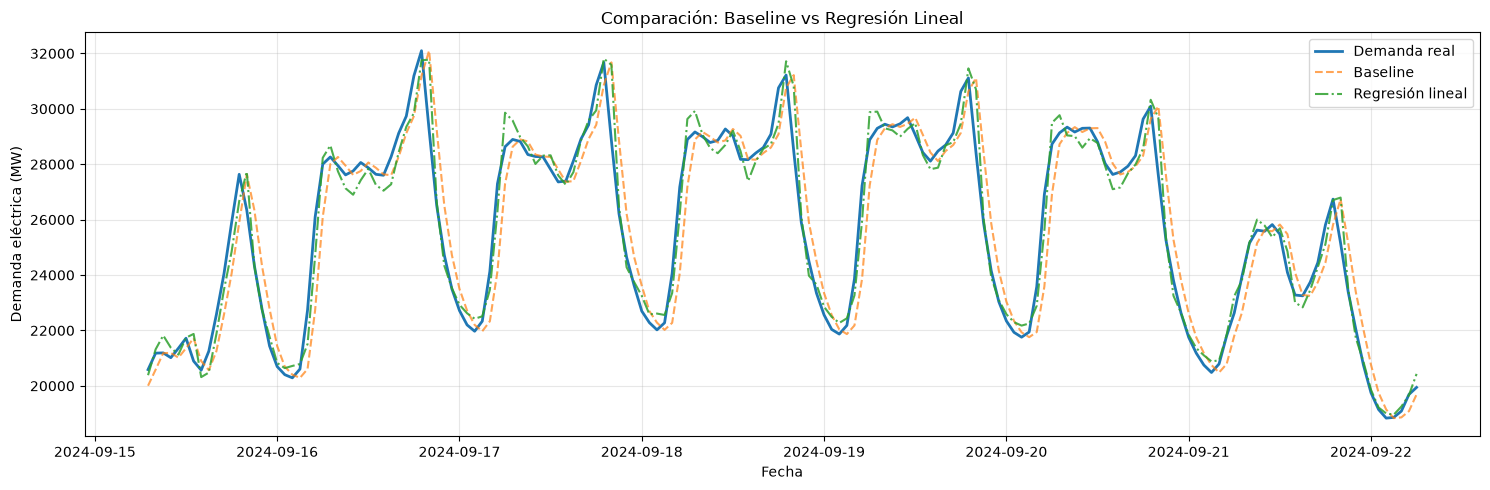

In [7]:
# Seleccionar una semana
n_hours = 168

dates = val_df["target_datetime_utc"].iloc[:n_hours]
real = y_val.iloc[:n_hours]
baseline = baseline_pred.iloc[:n_hours]
linear = linear_pred[:n_hours]

plt.figure(figsize=(15, 5))

plt.plot(
    dates,
    real,
    label="Demanda real",
    linewidth=2
)

plt.plot(
    dates,
    baseline,
    label="Baseline",
    linestyle="--",
    alpha=0.7
)

plt.plot(
    dates,
    linear,
    label="Regresión lineal",
    linestyle="-.",
    alpha=0.85
)

plt.title("Comparación: Baseline vs Regresión Lineal")
plt.xlabel("Fecha")
plt.ylabel("Demanda eléctrica (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 7.1. Interpretación de los resultados

La regresión lineal ha mejorado significativamente el rendimiento del modelo baseline sobre el conjunto de validación.

| Métrica | Baseline | Regresión lineal |
|---|---:|---:|
| MAE | 936,38 MW | 500,02 MW |
| RMSE | 1.273,22 MW | 667,13 MW |
| MAPE | 3,73 % | 1,94 % |

La reducción del MAE es aproximadamente del **46,60 %**, lo que demuestra que el uso conjunto de variables temporales, retardos y estadísticas móviles permite mejorar las predicciones frente a la persistencia.

La comparación gráfica muestra que la regresión lineal consigue seguir más de cerca la evolución de la demanda y anticipar parcialmente sus variaciones horarias.

Sin embargo, todavía se observan desviaciones durante determinados picos y descensos de consumo.

**Conclusión:** la regresión lineal constituye un primer modelo supervisado competitivo. El siguiente paso será evaluar algoritmos capaces de capturar relaciones no lineales y determinar si ofrecen mejoras adicionales.

Los resultados obtenidos corresponden al conjunto de validación y deberán confirmarse posteriormente sobre el conjunto de prueba.

## 8. Entrenamiento de Random Forest Regressor

### Objetivo

Evaluar un algoritmo de Machine Learning basado en árboles de decisión para determinar si puede mejorar las predicciones obtenidas mediante regresión lineal.

### Algoritmo seleccionado

Se utilizará `RandomForestRegressor` de Scikit-learn.

Random Forest es un algoritmo de aprendizaje supervisado que combina las predicciones de múltiples árboles de decisión.

Entre sus principales características destacan:

- Capacidad para aprender relaciones no lineales.
- Identificación de interacciones entre variables predictoras.
- Posibilidad de analizar la importancia relativa de las características.

### Metodología

El modelo se entrenará exclusivamente con el conjunto de entrenamiento y se evaluará sobre el mismo conjunto de validación utilizado para los modelos anteriores.

Se establecerán hiperparámetros iniciales para controlar la complejidad del modelo y facilitar la reproducibilidad de los resultados.

Posteriormente, se compararán las métricas MAE, RMSE y MAPE de los tres modelos.

In [8]:
from sklearn.ensemble import RandomForestRegressor

# Crear modelo Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Entrenar el modelo
rf_model.fit(X_train, y_train)

# Generar predicciones
rf_pred = rf_model.predict(X_val)

print("Random Forest entrenado correctamente.")
print("Predicciones generadas:", len(rf_pred))


Random Forest entrenado correctamente.
Predicciones generadas: 1292


In [9]:
# Evaluar Random Forest
rf_mae = mean_absolute_error(y_val, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_pred)
)

rf_mape = (
    mean_absolute_percentage_error(y_val, rf_pred) * 100
)

# Comparar los tres modelos
comparison_df = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Lineal",
        "Random Forest"
    ],
    "MAE (MW)": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE (MW)": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        linear_mape,
        rf_mape
    ]
})

display(
    comparison_df.sort_values("MAE (MW)").round(2)
)

# Comparar Random Forest con regresión lineal
improvement_rf = (
    (linear_mae - rf_mae) / linear_mae
) * 100

print(
    f"Mejora de Random Forest frente a regresión lineal: "
    f"{improvement_rf:.2f} %"
)


,Modelo,MAE (MW),RMSE (MW),MAPE (%)
2,Random Forest,365.53,496.69,1.43
1,Regresión Lineal,500.02,667.13,1.94
0,Baseline,936.38,1273.22,3.73


Mejora de Random Forest frente a regresión lineal: 26.90 %


## 9. Comparación visual de los modelos predictivos

Se representan las predicciones de los tres modelos desarrollados hasta el momento:

- Baseline de persistencia.
- Regresión lineal.
- Random Forest Regressor.

La comparación se realizará sobre las primeras 168 horas del conjunto de validación.

El objetivo es analizar visualmente qué modelo reproduce mejor los patrones de demanda, especialmente durante los cambios pronunciados y los máximos de consumo.

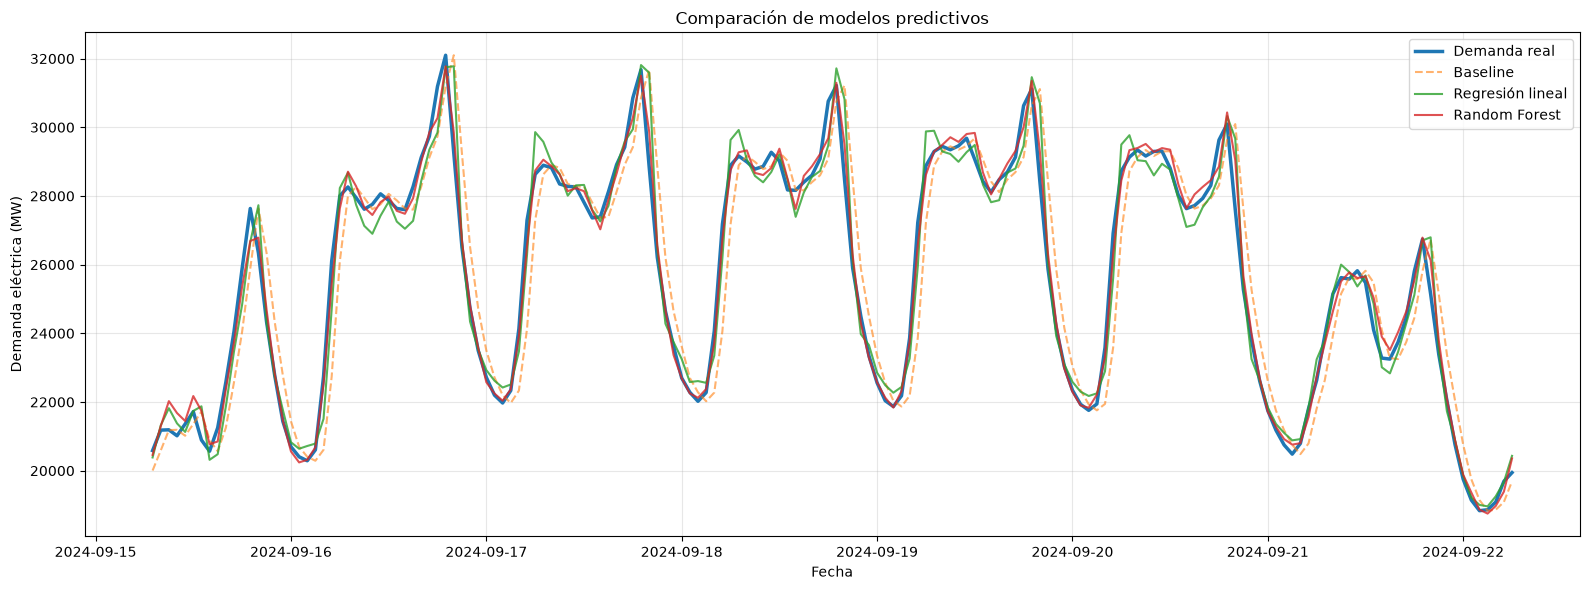

In [10]:
n_hours = 168

dates = val_df["target_datetime_utc"].iloc[:n_hours]

plt.figure(figsize=(16, 6))

plt.plot(
    dates,
    y_val.iloc[:n_hours],
    label="Demanda real",
    linewidth=2.5
)

plt.plot(
    dates,
    baseline_pred.iloc[:n_hours],
    label="Baseline",
    linestyle="--",
    alpha=0.6
)

plt.plot(
    dates,
    linear_pred[:n_hours],
    label="Regresión lineal",
    alpha=0.8
)

plt.plot(
    dates,
    rf_pred[:n_hours],
    label="Random Forest",
    alpha=0.8
)

plt.title("Comparación de modelos predictivos")
plt.xlabel("Fecha")
plt.ylabel("Demanda eléctrica (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### 9.1. Interpretación de los resultados

Se han evaluado tres modelos predictivos sobre el conjunto de validación, obteniendo los siguientes resultados:

| Modelo | MAE (MW) | RMSE (MW) | MAPE |
|---|---:|---:|---:|
| Baseline | 936,38 | 1.273,22 | 3,73 % |
| Regresión lineal | 500,02 | 667,13 | 1,94 % |
| Random Forest | **365,53** | **496,69** | **1,43 %** |

### Análisis comparativo

Random Forest ha obtenido el mejor rendimiento en las tres métricas de evaluación.

Respecto al modelo baseline, ha conseguido reducir el MAE aproximadamente un **60,96 %**. En comparación con la regresión lineal, la reducción del MAE ha sido del **26,90 %**.

La comparación visual muestra que Random Forest reproduce con mayor precisión los patrones de demanda eléctrica, especialmente durante las variaciones horarias.

Estos resultados sugieren que las relaciones no lineales entre las variables temporales y los valores históricos de demanda contribuyen a mejorar la capacidad predictiva.

### Conclusión

**Random Forest se selecciona provisionalmente como el modelo con mejor rendimiento**, al presentar los menores errores sobre el conjunto de validación.

El siguiente paso será analizar la importancia de las características predictoras y evaluar el modelo seleccionado sobre el conjunto de prueba, que se ha mantenido separado durante el entrenamiento y la selección.

## 10. Análisis de importancia de características

### Objetivo

Identificar las variables predictoras que tienen mayor influencia en las decisiones del modelo Random Forest.

### Metodología

Se utilizará el atributo `feature_importances_` de Scikit-learn, que calcula la importancia relativa de cada característica a partir de las reducciones de impureza producidas en los árboles de decisión.

Los resultados se representarán mediante un gráfico de barras ordenado de mayor a menor importancia.

### Consideraciones

La importancia de una característica no implica una relación causal con la demanda eléctrica.

Además, las variables históricas pueden estar correlacionadas entre sí, lo que puede afectar a la distribución de importancia entre ellas.

Este análisis permitirá interpretar el comportamiento del modelo, aunque no debe considerarse una medida definitiva de la contribución individual de cada variable.

,Característica,Importancia
4,lag_1,0.9028
0,hour,0.0418
7,lag_168,0.0286
5,lag_2,0.0098
6,lag_24,0.0084
8,rolling_mean_24,0.0024
2,month,0.0019
9,rolling_std_24,0.0014
10,rolling_mean_168,0.0013
1,day_of_week,0.0012


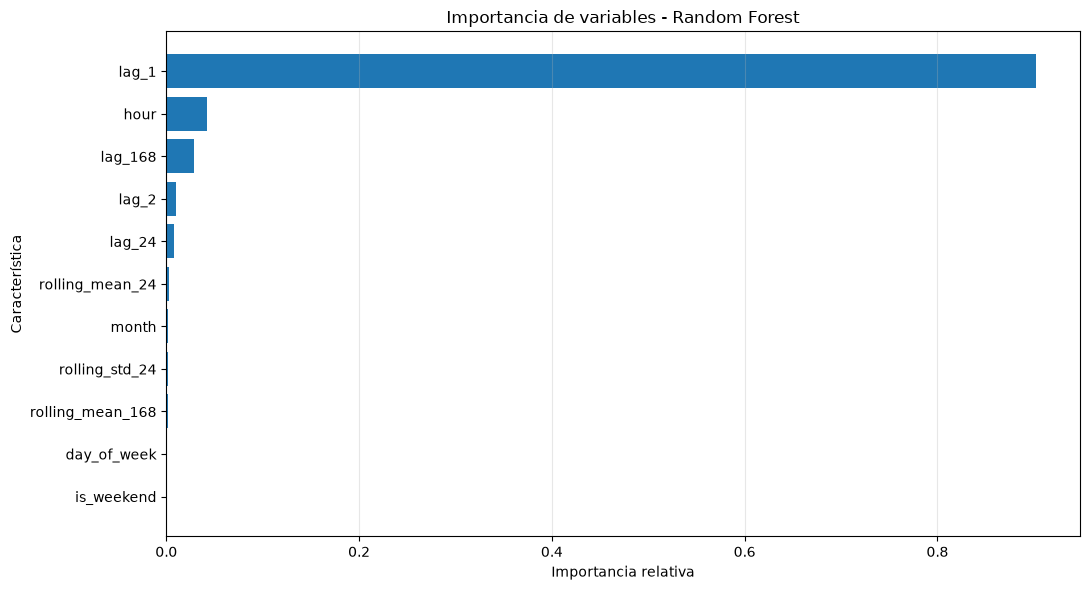

In [11]:
# Obtener importancia de características
feature_importance = pd.DataFrame({
    "Característica": feature_columns,
    "Importancia": rf_model.feature_importances_
})

# Ordenar de mayor a menor
feature_importance = feature_importance.sort_values(
    "Importancia",
    ascending=False
)

display(feature_importance.round(4))

# Visualizar importancia
plt.figure(figsize=(11, 6))

plt.barh(
    feature_importance["Característica"],
    feature_importance["Importancia"]
)

plt.gca().invert_yaxis()

plt.title("Importancia de variables - Random Forest")
plt.xlabel("Importancia relativa")
plt.ylabel("Característica")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()


## 11. Evaluación final sobre el conjunto de prueba

### Objetivo

Evaluar la capacidad de generalización del modelo seleccionado sobre observaciones posteriores a las utilizadas durante el entrenamiento y la validación.

### Metodología

Random Forest ha sido seleccionado por obtener el menor MAE en el conjunto de validación.

Una vez finalizada la selección, se reentrenará utilizando conjuntamente los conjuntos de entrenamiento y validación, manteniendo los hiperparámetros establecidos.

Posteriormente, se generarán predicciones sobre el conjunto de prueba, que comprende las últimas semanas de 2024.

Las métricas MAE, RMSE y MAPE permitirán comprobar si el rendimiento observado durante la validación se mantiene en un periodo temporal diferente.

El conjunto de prueba no se utilizará para modificar los hiperparámetros ni seleccionar un nuevo modelo.

In [12]:
# Combinar entrenamiento y validación
train_val_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

X_train_val = train_val_df[feature_columns]
y_train_val = train_val_df[target_column]

# Preparar conjunto de prueba
X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Reentrenar Random Forest
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_val, y_train_val)

# Predecir sobre el conjunto de prueba
test_pred = final_model.predict(X_test)

# Calcular métricas finales
test_mae = mean_absolute_error(y_test, test_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

test_mape = (
    mean_absolute_percentage_error(y_test, test_pred)
    * 100
)

# Evaluar baseline sobre el mismo conjunto
baseline_test_pred = test_df["lag_1"]

baseline_test_mae = mean_absolute_error(
    y_test,
    baseline_test_pred
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_test_pred)
)

baseline_test_mape = (
    mean_absolute_percentage_error(
        y_test,
        baseline_test_pred
    ) * 100
)

# Tabla comparativa
test_results = pd.DataFrame({
    "Modelo": ["Baseline", "Random Forest"],
    "MAE (MW)": [baseline_test_mae, test_mae],
    "RMSE (MW)": [baseline_test_rmse, test_rmse],
    "MAPE (%)": [baseline_test_mape, test_mape]
})

print("RESULTADOS FINALES - TEST")
print("------------------------")
display(test_results.round(2))

print(
    "Reducción del MAE frente al baseline:",
    f"{(1 - test_mae / baseline_test_mae) * 100:.2f} %"
)


RESULTADOS FINALES - TEST
------------------------


,Modelo,MAE (MW),RMSE (MW),MAPE (%)
0,Baseline,1066.45,1448.73,4.03
1,Random Forest,448.16,626.14,1.66


Reducción del MAE frente al baseline: 57.98 %


## 12. Visualización de las predicciones finales

Se comparan las predicciones del modelo Random Forest con los valores reales de demanda eléctrica durante una semana del conjunto de prueba.

Esta representación permite observar el comportamiento del modelo seleccionado sobre datos que no han intervenido en su entrenamiento ni en su selección.

La visualización complementa las métricas cuantitativas y facilita la identificación de posibles desviaciones durante los máximos, mínimos y cambios de demanda.

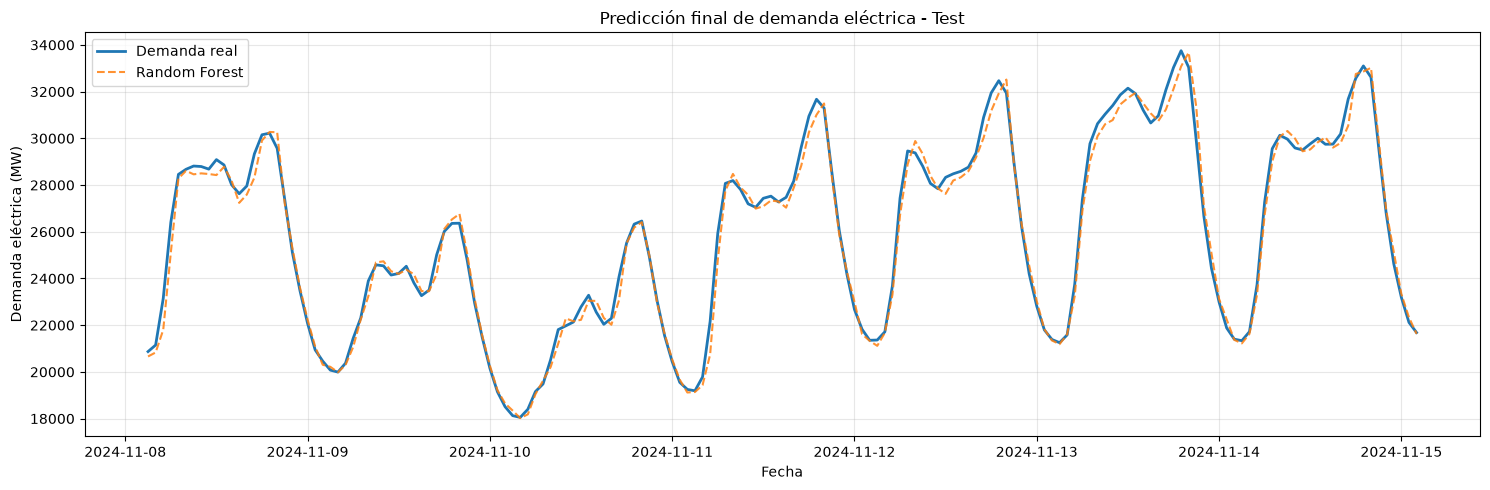

In [13]:
n_hours = 168

plt.figure(figsize=(15, 5))

plt.plot(
    test_df["target_datetime_utc"].iloc[:n_hours],
    y_test.iloc[:n_hours],
    label="Demanda real",
    linewidth=2
)

plt.plot(
    test_df["target_datetime_utc"].iloc[:n_hours],
    test_pred[:n_hours],
    label="Random Forest",
    linestyle="--",
    alpha=0.85
)

plt.title("Predicción final de demanda eléctrica - Test")
plt.xlabel("Fecha")
plt.ylabel("Demanda eléctrica (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 12.1. Interpretación de los resultados finales

El modelo Random Forest ha sido evaluado sobre el conjunto de prueba, compuesto por 1.293 observaciones correspondientes al periodo comprendido entre el 8 de noviembre y el 31 de diciembre de 2024.

### Resultados obtenidos

| Métrica | Baseline | Random Forest |
|---|---:|---:|
| MAE | 1.066,45 MW | **448,16 MW** |
| RMSE | 1.448,73 MW | **626,14 MW** |
| MAPE | 4,03 % | **1,66 %** |

### Análisis de rendimiento

Random Forest ha conseguido reducir el error absoluto medio un **57,98 % respecto al baseline**, confirmando que el uso de características temporales, retardos y estadísticas móviles permite mejorar significativamente las predicciones de persistencia.

El modelo obtiene un MAPE del 1,66 %, lo que indica que el error porcentual absoluto medio es relativamente reducido en el periodo evaluado.

La comparación visual muestra que las predicciones reproducen de forma aproximada los patrones diarios de demanda, incluyendo máximos y mínimos.

### Comparación entre validación y prueba

El MAE obtenido durante la validación fue de 365,53 MW, mientras que en prueba aumentó hasta 448,16 MW.

Esta diferencia evidencia que el rendimiento predictivo puede variar entre periodos temporales. Además, el modelo final se ha reentrenado utilizando conjuntamente los datos de entrenamiento y validación.

### Conclusión

**Random Forest ha demostrado una capacidad predictiva superior al modelo de persistencia tanto en validación como en prueba.**

Los resultados respaldan su selección como modelo principal de EnergyPredict AI para la predicción de demanda eléctrica a una hora vista.

No obstante, la evaluación se limita a datos de 2024. Para estudiar su capacidad de generalización a largo plazo sería conveniente incorporar otros años y realizar evaluaciones temporales adicionales.

## 13. Persistencia del modelo entrenado

### Objetivo

Guardar el modelo Random Forest seleccionado para permitir su reutilización en futuras ejecuciones del proyecto.

### Metodología

Se utilizará la librería `joblib` para serializar el modelo entrenado y almacenarlo en un archivo.

Esto permitirá:

- Recuperar el modelo sin repetir el entrenamiento.
- Generar predicciones desde scripts Python independientes.
- Integrar el modelo en una futura aplicación o API.
- Facilitar la reproducibilidad del proyecto.

El modelo guardado corresponderá a la versión entrenada con los conjuntos de entrenamiento y validación, y evaluada posteriormente sobre el conjunto de prueba.

In [14]:
from pathlib import Path
import joblib

# Crear directorio para modelos
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Ruta del modelo
model_path = models_dir / "random_forest_v1.joblib"

# Guardar modelo y metadatos necesarios
model_artifact = {
    "model": final_model,
    "feature_columns": feature_columns,
    "target_column": target_column,
    "prediction_horizon_hours": 1,
    "model_version": "1.0"
}

joblib.dump(model_artifact, model_path)

print("Modelo guardado correctamente:")
print(model_path.resolve())


Modelo guardado correctamente:
/workspaces/EnergyPredict-AI/models/random_forest_v1.joblib


In [15]:
# Cargar modelo desde disco
loaded_artifact = joblib.load(model_path)

loaded_model = loaded_artifact["model"]
loaded_features = loaded_artifact["feature_columns"]

# Realizar predicciones con el modelo recuperado
loaded_predictions = loaded_model.predict(
    X_test[loaded_features]
)

# Comprobar que coinciden con las originales
assert np.allclose(
    loaded_predictions,
    test_pred
), "Las predicciones no coinciden."

print("Modelo recuperado correctamente.")
print("Versión:", loaded_artifact["model_version"])
print("Número de características:", len(loaded_features))
print("Predicciones verificadas:", len(loaded_predictions))


Modelo recuperado correctamente.
Versión: 1.0
Número de características: 11
Predicciones verificadas: 1293


## 14. Integración y verificación del sistema de predicción

### Objetivo

Comprobar que el modelo Random Forest entrenado y almacenado puede utilizarse desde un script Python independiente, sin necesidad de ejecutar nuevamente el notebook de entrenamiento.

Esta fase constituye el primer paso hacia la integración del modelo en una aplicación de predicción de demanda eléctrica.

### Implementación

Se ha desarrollado el archivo `predict.py`, ubicado en la raíz del proyecto EnergyPredict AI.

El script realiza las siguientes operaciones:

1. **Carga del modelo:** recupera el archivo `models/random_forest_v1.joblib` mediante la librería `joblib`.
2. **Recuperación de metadatos:** obtiene el modelo entrenado y las 11 características predictoras utilizadas durante el entrenamiento.
3. **Carga de datos:** accede al dataset procesado `features_spain_2024.parquet`.
4. **Selección de observación:** identifica el último registro disponible, ordenando las observaciones cronológicamente.
5. **Generación de predicción:** utiliza el modelo Random Forest para estimar la demanda eléctrica correspondiente a la fecha objetivo del registro seleccionado.
6. **Presentación del resultado:** muestra la fecha de predicción y la demanda estimada en megavatios (MW).

### Ejecución

El sistema se ejecuta desde la terminal, situándose en la raíz del proyecto:

```bash
python predict.py
```

Esta ejecución permite utilizar el modelo previamente entrenado sin depender del entorno de Jupyter Notebook.

### Resultados obtenidos

La ejecución del script se ha completado correctamente, obteniendo el siguiente resultado:

```text
ENERGYPREDICT AI
--------------------------
Modelo: Random Forest
Fecha objetivo: 2024-12-31 23:00:00+00:00
Demanda estimada: 23,121.82 MW
```

El modelo ha generado una estimación de **23.121,82 MW** para el 31 de diciembre de 2024 a las 23:00 UTC.

### Consideraciones

La predicción realizada utiliza una observación histórica del conjunto de datos de 2024.

Por tanto, esta prueba no constituye una predicción en tiempo real ni una estimación sobre datos futuros todavía desconocidos.

Su finalidad es verificar que:

- El modelo serializado puede recuperarse correctamente.
- Las características predictoras mantienen la estructura utilizada durante el entrenamiento.
- El sistema puede generar predicciones desde un archivo Python independiente.
- El proceso de inferencia funciona sin necesidad de repetir el entrenamiento.

### Próximos pasos

Para convertir este prototipo en un sistema de predicción operativo, será necesario:

1. Automatizar la generación de características a partir de los datos históricos disponibles.
2. Incorporar datos de demanda más recientes.
3. Permitir predicciones sobre horas futuras sin utilizar información posterior al instante de predicción.
4. Desarrollar una API mediante FastAPI para facilitar el acceso al modelo desde otras aplicaciones.

### Conclusión

**Se ha completado satisfactoriamente la primera integración del modelo Random Forest en un sistema de inferencia independiente.**

EnergyPredict AI dispone ahora de un modelo entrenado, evaluado, almacenado y reutilizable desde Python.

Este resultado establece la base técnica para desarrollar un servicio de predicción de demanda eléctrica automatizado.